# E4 Faux positifs : un classifieur derrière le U-Net

Le point faible du modèle, ce sont les fausses détections, surtout sur les images sans racine (notebook 07). Plutôt que de réentraîner le U-Net, on lui ajoute un **deuxième étage** léger : chaque tache qu'il prédit est décrite (taille, probabilité, forme, contexte de l'image), puis un **classifieur** décide de la garder ou de la retirer.

**L'essentiel** : sur les 1 000 images de validation, le classifieur divise par 2,4 les taches fausses (fantômes 801 → 327) et fait passer les images sans racine touchées de 47 % à 13 %, pour un coût limité : 1,6 point de racines trouvées en moins, longueur et diamètre presque inchangés. Il s'appuie surtout sur le contexte de l'image (surface prédite, nombre de taches) et sur la probabilité maximale de la tache. Mesure finale sur le test, avec la segmentation (notebook 07).

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / 'src'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.inspection import permutation_importance

from prmi import blob_classifier as bc, postprocess as pp, viz
from prmi.dataset import VAL_LARGE, draw_extra, load_extra, val_learning
from prmi.train import RUNS_DIR, blob_crops, blob_table, load_run, postprocess_study, summarize, trait_scores

viz.apply_style()
pd.set_option('display.width', 180)
%config InlineBackend.figure_formats = ['jpeg']
plt.rcParams['figure.dpi'] = 90

NAME = 'unet_effb0_tout'                   # U-Net, version 1
SCALE = 2

## 1. Les taches prédites

Chaque prédiction du U-Net est découpée en taches (morceaux connexes). Une tache est **vraie** si elle touche une racine de la référence, **fausse** sinon. Calculé une fois (environ 10 min, clé branchée), puis relu.

In [2]:
model = load_run(NAME)[0]
device = next(model.parameters()).device
train_rows, val_rows = val_learning(), draw_extra(1000, path=VAL_LARGE, split='val')
train_images, learn = blob_table(NAME, 'val_appr', rows=train_rows)
val_images, val = blob_table(NAME, 'val_large', rows=val_rows)
pd.DataFrame({k: {'images': len(im), 'taches': len(b), 'vraies': int(b['vraie'].sum()), 'fausses': int((~b['vraie']).sum())}
              for k, (im, b) in {'entraînement': (train_images, learn), 'validation': (val_images, val)}.items()}).T

,images,taches,vraies,fausses
entraînement,2273,6528,3587,2941
validation,1000,2813,1536,1277


## 2. À quoi ressemblent les faux positifs

Exploration sur l'ensemble d'entraînement. Vignettes centrées sur des taches : à gauche l'image (tache fausse en contour rouge, vraie en noir ; référence en bleu), à droite la carte de probabilité du U-Net. Titre : taille, probabilité moyenne, allongement.

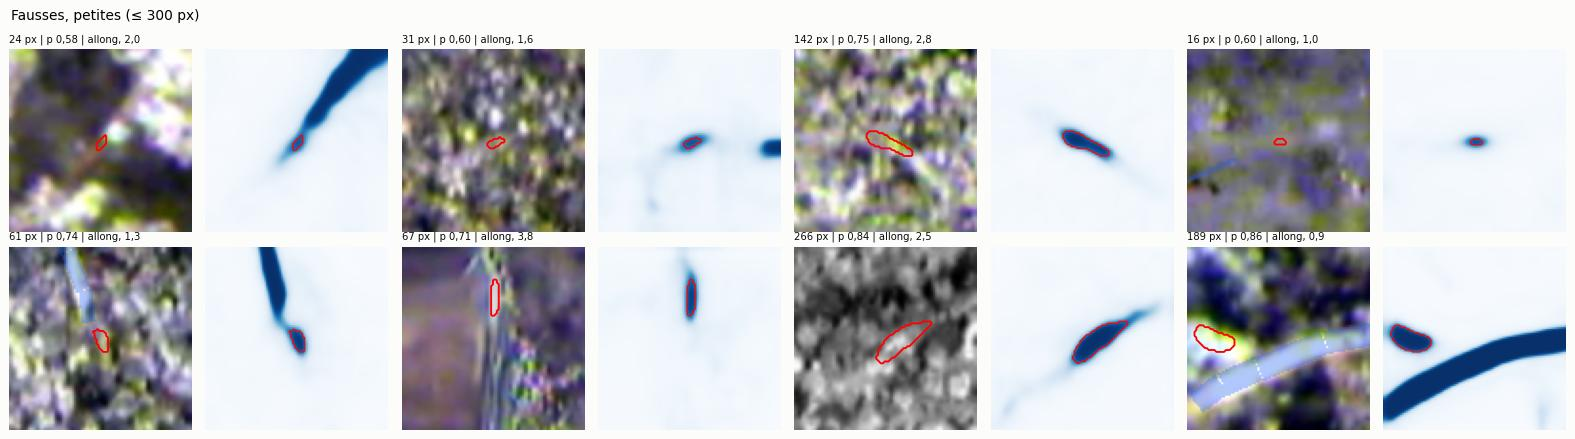

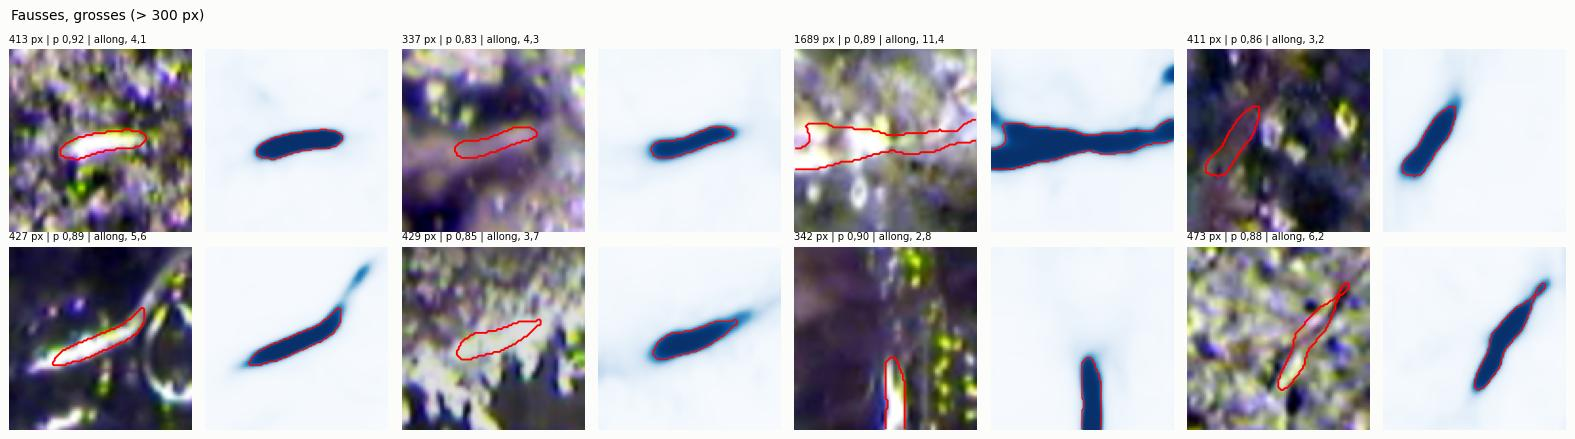

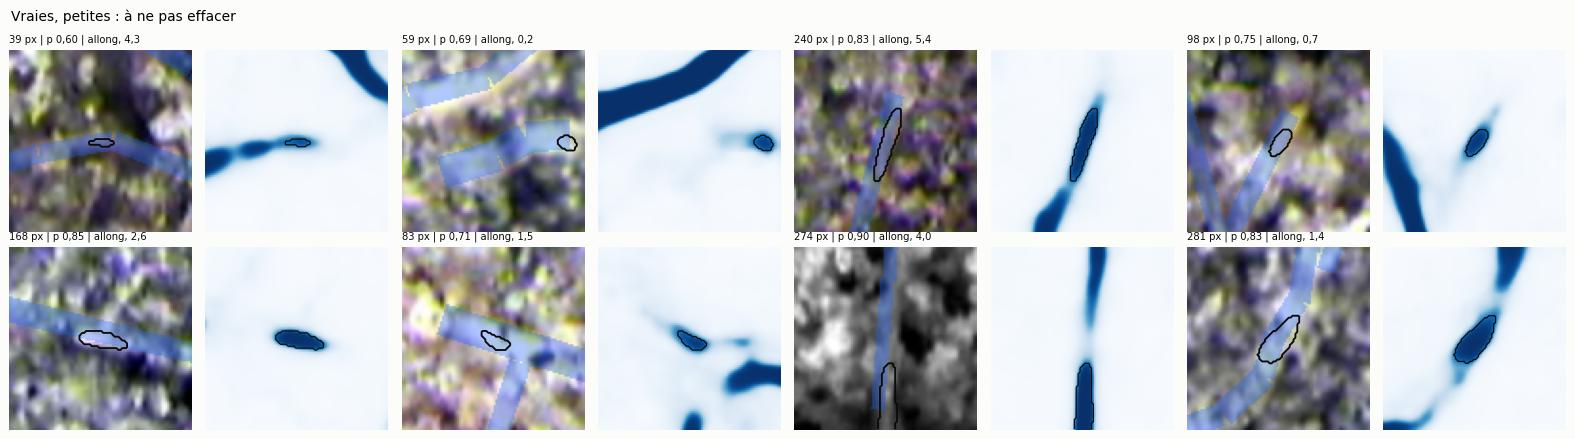

In [3]:
SMALL = 300                                # px : seuil de taille pour la galerie seulement
false = learn[~learn['vraie'].astype(bool)]
picks = {f'Fausses, petites (≤ {SMALL} px)': false[false['px'] <= SMALL],
         f'Fausses, grosses (> {SMALL} px)': false[false['px'] > SMALL],
         'Vraies, petites : à ne pas effacer': learn[learn['vraie'].astype(bool) & (learn['px'] <= SMALL)]}
sample = {k: b.sample(8, random_state=0) for k, b in picks.items()}
names = pd.concat(sample.values())['name'].unique()
items = {it['name']: it for it in load_extra(train_rows[train_rows['name'].isin(names)], SCALE)}
for title, b in sample.items():
    fig = viz.blob_gallery(blob_crops(model, items, b, device))
    fig.suptitle(title, x=0.01, ha='left', fontsize=11)
    fig.tight_layout()
    plt.show()

- **Petites taches fausses** : grains clairs du sol, reflets, courts bouts isolés, plutôt trapus.
- **Grosses taches « fausses »** : beaucoup ressemblent à de vraies racines oubliées par l'annotation PRMI.
- **Vraies petites taches** : surtout des morceaux d'une racine prédite en pointillés.

## 3. Probabilité et taille

Chaque point est une tache de l'ensemble d'entraînement. Les taches fausses sont surtout petites et un peu moins sûres, mais les deux nuages se recouvrent : aucun seuil simple ne les sépare, d'où l'intérêt d'un classifieur qui combine tous les descripteurs.

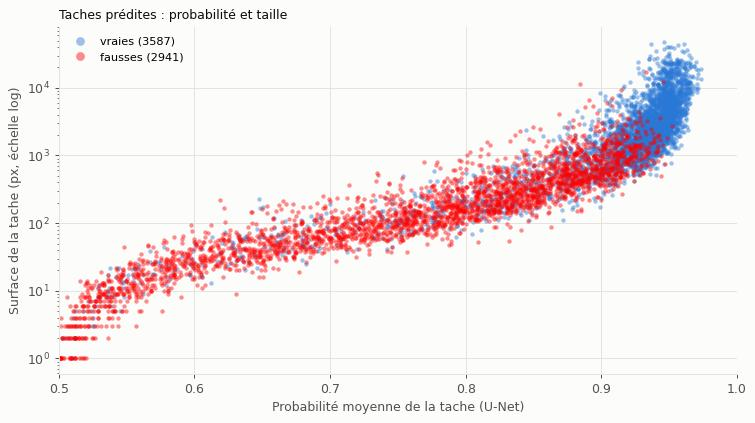

In [4]:
viz.save(viz.plot_blobs(learn), 'E4_taches.png');

## 4. Le classifieur

### Les entrées

Une ligne par tache prédite, 13 descripteurs, et la réponse à apprendre : la tache est-elle **vraie** ?

| Descripteur | Ce qu'il mesure |
|---|---|
| `px` | surface de la tache (pixels, résolution d'origine) |
| `p_moy`, `p_max` | probabilité moyenne et maximale donnée par le U-Net dans la tache |
| `longueur` | longueur de son squelette (px) |
| `largeur` | largeur moyenne : surface / longueur |
| `allongement` | longueur / largeur (une racine est longue et fine) |
| `p_trainee`, `p_trainee_90` | probabilité moyenne et centile 90 dans un anneau de 6 px autour de la tache, hors prédiction : la « traînée » qui prolonge un morceau de racine |
| `dist_voisine`, `px_voisine` | distance à la tache la plus proche et surface de celle-ci |
| `dist_bord` | distance au bord de l'image |
| `n_taches`, `px_image` | nombre de taches et surface totale prédite dans l'image |

In [5]:
FEATURES = bc.FEATURES
learn[FEATURES + ['vraie']].sample(6, random_state=0).round(2)

,px,p_moy,p_max,longueur,largeur,allongement,p_trainee,p_trainee_90,dist_voisine,px_voisine,dist_bord,n_taches,px_image,vraie
2527,213,0.80,0.97,24,8.88,2.70,0.13,0.38,100.57,4324,0,7,6676,False
2631,860,0.92,1.00,46,18.70,2.46,0.09,0.30,920.00,0,0,1,860,False
2377,6901,0.92,1.00,382,18.07,21.15,0.10,0.33,5.00,3790,0,4,13396,True
1514,319,0.75,0.94,47,6.79,6.92,0.11,0.37,97.59,211,101,5,1527,False
3655,277,0.86,0.98,29,9.55,3.04,0.11,0.34,15.23,569,229,7,6373,False
5358,1998,0.92,1.00,154,12.97,11.87,0.07,0.26,77.67,2793,130,2,4791,True


### Le modèle

Un **gradient boosting** sur histogrammes (`HistGradientBoostingClassifier` de scikit-learn, même algorithme que LightGBM) : des centaines de petits arbres de décision, chacun corrigeant les erreurs des précédents ; la méthode de référence sur ce type de données tabulaires. Réglages : arbres de profondeur 6 au plus, taux d'apprentissage 0,1, au moins 10 taches par feuille, jusqu'à 500 arbres. Toutes les taches d'entraînement sont apprises ; l'apprentissage s'arrête quand l'erreur sur la **validation** ne baisse plus depuis 30 arbres.

In [6]:
from sklearn.ensemble import HistGradientBoostingClassifier

clf = HistGradientBoostingClassifier(max_depth=6, learning_rate=0.1, max_iter=500, min_samples_leaf=10,
                                     early_stopping=True, n_iter_no_change=30, scoring='loss', random_state=0)
clf.fit(learn[FEATURES], learn['vraie'], X_val=val[FEATURES], y_val=val['vraie'])
print(f"{len(learn)} taches d'entraînement, {len(val)} de validation ; arrêt à {clf.n_iter_} arbres")

6528 taches d'entraînement, 2813 de validation ; arrêt à 80 arbres


### Apprentissage et scores

Courbe d'apprentissage : perte logistique à chaque arbre ajouté, sur l'entraînement et sur la validation. Puis les scores sur les deux ensembles :
- **AUC ROC** : probabilité qu'une tache vraie tirée au hasard ait un score plus haut qu'une fausse (0,5 = hasard, 1 = parfait) ;
- **précision moyenne** : aire sous la courbe précision / rappel ;
- **perte logistique** et **exactitude** au seuil 0,5 ;
- en comparaison, l'AUC de la seule probabilité moyenne du U-Net : ce qu'apporte le classifieur.

,taches,AUC ROC,précision moyenne,perte logistique,"exactitude (seuil 0,5)",AUC de p_moy seule
entraînement,6528.0,0.982,0.986,0.189,0.924,0.892
validation,2813.0,0.942,0.957,0.305,0.861,0.899


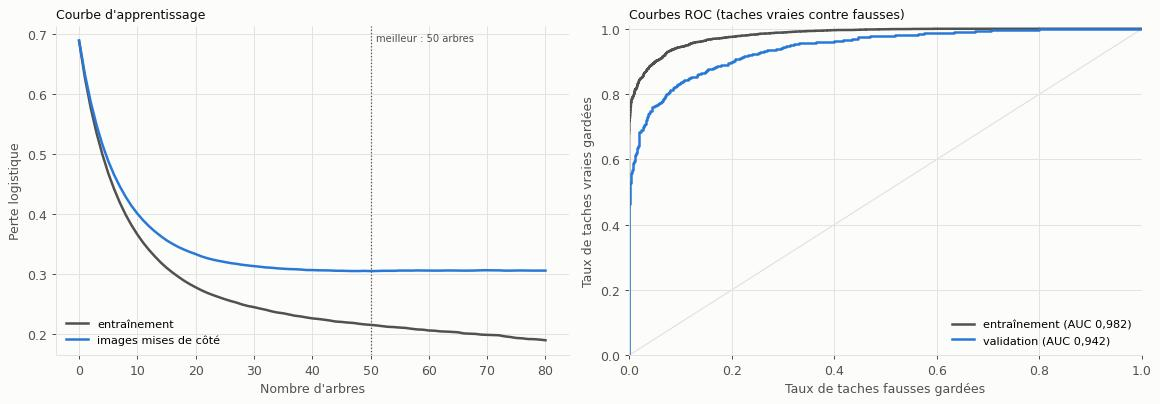

In [7]:
from sklearn.metrics import accuracy_score, average_precision_score, log_loss, roc_auc_score

sets = {'entraînement': learn, 'validation': val}
scores, rows = {}, {}
for k, b in sets.items():
    y, s = b['vraie'].astype(bool).to_numpy(), bc.p_true(clf, b)
    scores[k] = (y, s)
    rows[k] = {'taches': len(b), 'AUC ROC': roc_auc_score(y, s), 'précision moyenne': average_precision_score(y, s),
               'perte logistique': log_loss(y, s), 'exactitude (seuil 0,5)': accuracy_score(y, s >= 0.5),
               'AUC de p_moy seule': roc_auc_score(y, b['p_moy'])}
viz.save(viz.plot_classifier(clf, scores), 'E4_apprentissage.png')
pd.DataFrame(rows).T.round(3)

**Lecture**
- **Apprentissage** : l'erreur de validation cesse de baisser après 50 arbres (perte 0,305) ; l'arrêt précoce attend 30 arbres de plus et scikit-learn garde les 80, sans effet sur l'erreur de validation.
- **Généralisation** : écart habituel d'un boosting entre entraînement (AUC 0,982) et validation (0,942).
- **Apport** : sur la validation, une AUC de 0,942 contre 0,899 pour la seule probabilité moyenne du U-Net.

Ce qui compte pour le classifieur : baisse de l'AUC quand on mélange au hasard chaque descripteur (sur la validation, 10 répétitions).

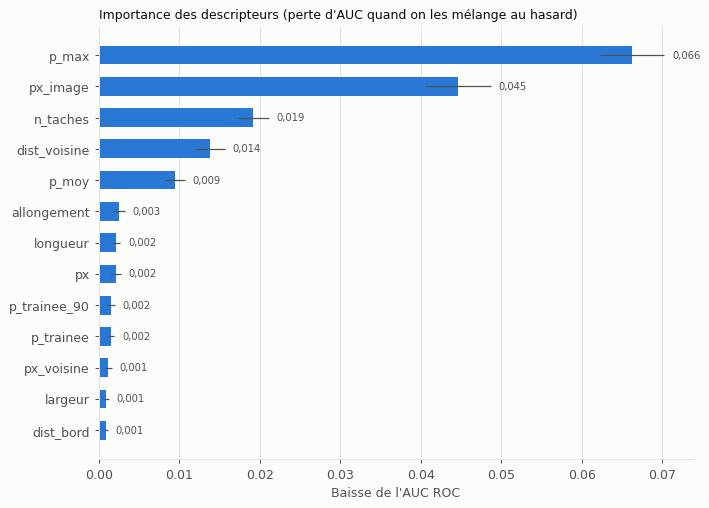

In [8]:
imp = permutation_importance(clf, val[FEATURES], val['vraie'], scoring='roc_auc', n_repeats=10, random_state=0)
viz.save(viz.plot_importance(pd.Series(imp.importances_mean, index=FEATURES), pd.Series(imp.importances_std, index=FEATURES)),
         'E4_importance.png');

### Le seuil

Le classifieur donne à chaque tache une probabilité d'être vraie ; on retire les taches sous un **seuil**. Un seuil bas ne retire que les taches presque sûrement fausses ; un seuil haut en retire plus, au risque d'effacer de vraies racines. Le seuil se choisit après l'apprentissage, **sur la validation** : on accepte de perdre au plus **0,5 % de la longueur de racine**, et on prend le seuil qui retire le plus de taches fausses dans cette limite.

seuil retenu : 0.240


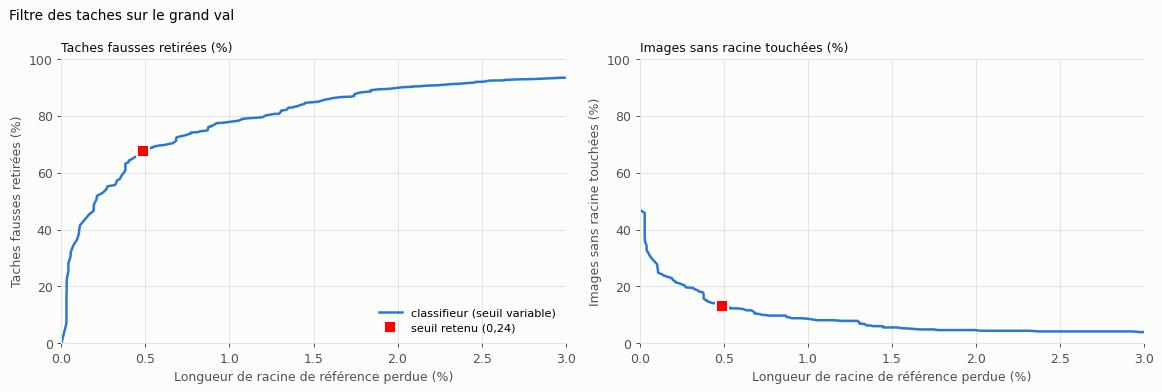

In [9]:
curve = bc.tradeoff(val_images, val, bc.p_true(clf, val))
TAU = bc.threshold_for(curve, 0.005)
bc.save(clf, TAU, RUNS_DIR / NAME / 'classifieur_taches.joblib')
print(f'seuil retenu : {TAU:.3f}')
viz.save(viz.plot_tradeoff(curve, {f'seuil retenu ({TAU:.2f})'.replace('.', ','): curve[curve['seuil'] == TAU].iloc[0]}),
         'E4_seuil.png')

### Taches ou pixels ?

Les scores ci-dessus comptent chaque tache une fois, qu'elle fasse 10 px ou 10 000 px, le Dice, lui, compte les pixels. Mêmes mesures, pondérées par la surface des taches :

In [10]:
y, px = val['vraie'].astype(bool).to_numpy(), val['px'].to_numpy()
s, gone = bc.p_true(clf, val), bc.p_true(clf, val) < TAU
display(pd.DataFrame({name: {'par tache': roc_auc_score(y, sc), 'pondérée par la surface': roc_auc_score(y, sc, sample_weight=px)}
                      for name, sc in {'probabilité moyenne du U-Net': val['p_moy'], 'classifieur': s}.items()}).T.round(3).rename_axis('AUC ROC'))
pd.DataFrame({'en nombre de taches': {'fausses retirées': gone[~y].mean(), 'vraies retirées': gone[y].mean()},
              'en surface': {'fausses retirées': px[gone & ~y].sum() / px[~y].sum(), 'vraies retirées': px[gone & y].sum() / px[y].sum()}}
             ).round(3).rename_axis(f'au seuil {TAU:.2f}')

,par tache,pondérée par la surface
AUC ROC,,
probabilité moyenne du U-Net,0.899,0.955
classifieur,0.942,0.975


,en nombre de taches,en surface
au seuil 0.24,,
fausses retirées,0.677,0.434
vraies retirées,0.048,0.005


- **Pondérées par la surface, les deux AUC montent** : les grosses taches sont faciles à classer (une grosse racine est presque toujours très sûre). Le classifieur reste devant, mais c'est sur les petites taches qu'il apporte le plus.
- **Il retire surtout des petites taches** : 68 % des taches fausses en nombre, 43 % en surface. Les grosses taches fausses (plus de 1 000 px, la moitié de la surface fausse) restent en grande partie, et beaucoup sont des racines oubliées par l'annotation PRMI (galerie).
- **Les vraies taches qu'il efface sont minuscules** : 4,8 % en nombre, 0,5 % en surface. D'où un Dice global qui bouge peu : son apport est dans les fausses alertes, pas dans la précision au pixel.

## 5. Effet sur la validation

Le U-Net seul, puis avec le classifieur, image par image sur les 1 000 images de validation : Dice global, racines trouvées, fantômes (taches fausses d'au moins 100 px), images sans racine touchées, et biais d'ensemble de la longueur et du diamètre (somme prédite / somme de référence - 1). Calculé une fois (environ 5 min), puis relu.

,global_dice,roots_found,ghosts,fp_empty,longueur : biais d'ensemble,diamètre : biais d'ensemble
U-Net seul,0.721,0.698,801.0,0.470,-0.216,0.291
U-Net + classifieur,0.732,0.682,327.0,0.132,-0.231,0.300


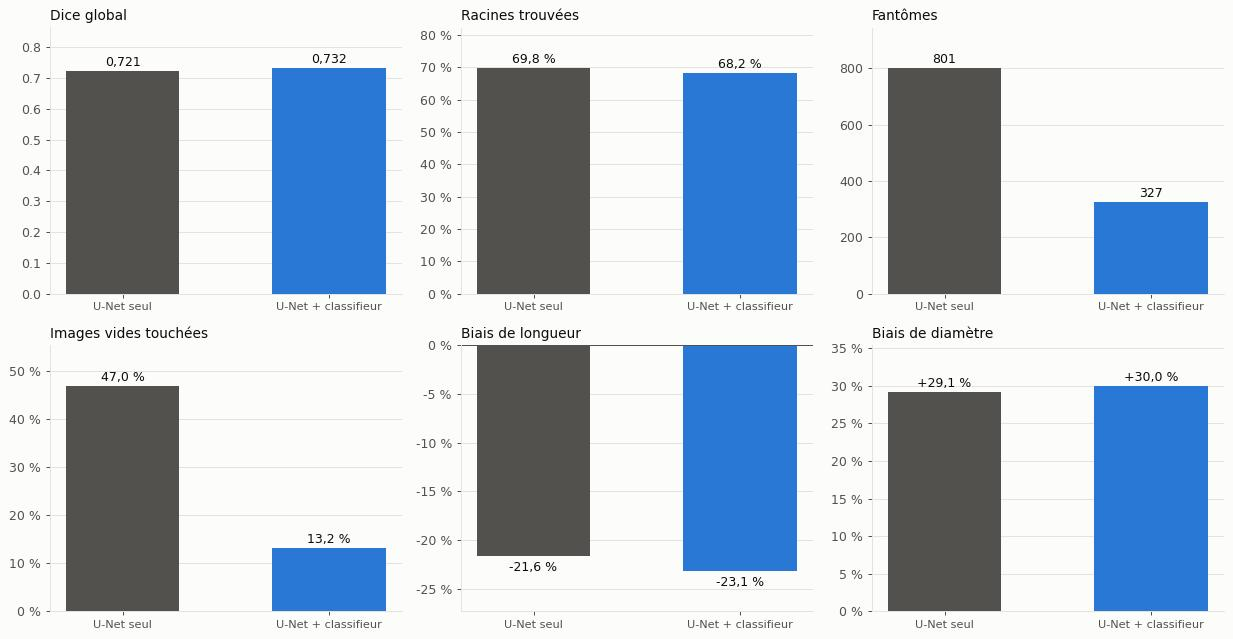

In [11]:
options = {'U-Net seul': lambda p: p > 0.5, 'U-Net + classifieur': lambda p: bc.classifier_filter(p, clf, TAU)}
METRICS = ['global_dice', 'roots_found', 'ghosts', 'fp_empty', "longueur : biais d'ensemble", "diamètre : biais d'ensemble"]
result = postprocess_study(NAME, 'val_large_classifieur', options, rows=val_rows)
table = pd.DataFrame({v: {**summarize(g), **trait_scores(g)} for v, g in result.groupby('variante', sort=False)}).T[METRICS]
viz.save(viz.plot_compare(table, METRICS), 'E4_resultat_validation.png')
table.round(3)

**À retenir**
- **Moins de fausses alertes** : fantômes 801 → 327, images sans racine touchées 47 % → 13 %, Dice global 0,721 → 0,732.
- **Coût limité** : racines trouvées 69,8 % → 68,2 % ; biais de longueur -21,6 % → -23,1 % ; diamètre inchangé (+29 % → +30 %) ; 0,5 % de la longueur de racine perdue, comme demandé au seuil.
- **Ces chiffres sont un peu optimistes** : la validation a servi à arrêter l'apprentissage et à choisir le seuil. La mesure honnête se fera sur le test, avec la segmentation (version 1.1 : U-Net + classifieur, notebook 07).
- **Limite** : appris sur l'annotation PRMI, où les racines faibles oubliées comptent comme fausses ; une partie des taches retirées peuvent être de vraies racines. Le test corrigé à la main le dira.

## Essai écarté : seuillage par hystérésis

Deux seuils au lieu d'un : on garde les pixels très sûrs (graine) et les pixels moins sûrs qui leur sont reliés (prolongement), pour rattacher aux racines leurs traînées peu sûres (`pp.hysteresis`). Sur la validation : jusqu'à +2,3 points de racines trouvées, mais le biais de diamètre passe de +29 % à +40 % (les pixels peu sûrs sont aussi les bords des racines), et les faux positifs ne baissent presque pas. **Non retenu.** Pour récupérer la longueur des racines en pointillés, il faudra plutôt reconnecter les morceaux le long de leur axe, au moment de mesurer les traits.

In [12]:
variants = pp.variants()
hyst = postprocess_study(NAME, 'val_large', variants, rows=val_rows)
hyst = hyst[hyst['variante'].isin(variants)]
pd.DataFrame({v: {**summarize(g), **trait_scores(g)} for v, g in hyst.groupby('variante', sort=False)}).T[METRICS].round(3)

,global_dice,roots_found,ghosts,fp_empty,longueur : biais d'ensemble,diamètre : biais d'ensemble
sans post-traitement,0.721,0.698,801.0,0.470,-0.216,0.291
"hystérésis 0,5 / 0,2",0.718,0.721,976.0,0.505,-0.203,0.399
"hystérésis 0,5 / 0,3",0.720,0.713,903.0,0.488,-0.208,0.357
"hystérésis 0,8 / 0,2",0.719,0.720,889.0,0.491,-0.206,0.403
"hystérésis 0,8 / 0,3",0.721,0.712,863.0,0.477,-0.211,0.360
"hystérésis 0,8 / 0,5",0.722,0.697,794.0,0.465,-0.218,0.294
"hystérésis 0,9 / 0,2",0.720,0.719,786.0,0.477,-0.209,0.405
"hystérésis 0,9 / 0,3",0.722,0.711,783.0,0.468,-0.213,0.362
"hystérésis 0,9 / 0,5",0.722,0.696,761.0,0.458,-0.220,0.296
